# House Prices — исследовательский анализ данных (EDA)

Нужно понять структуру данных, качество признаков и их связь с SalePrice,
чтобы составить гипотезы для будущих экспериментов. Одна строка — запись о продаже дома.
Данные — локальные data/regression/train.csv и test.csv; смысл полей — data_description.txt.

Исследуем цены только в train. Исходные CSV не меняем, модели здесь не обучаем!!
Запускать сверху вниз с ядром Python (ml_project), рабочая папка — notebooks.

## 1. Окружение и загрузка

In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

print("Python:", sys.executable)
print("Work dir:", Path.cwd())
print("pandas:", pd.__version__)
sns.set_theme(style="whitegrid")
price_formatter = FuncFormatter(lambda value, position: f"{value / 1000:.0f}k")

Python: C:\Users\toni1\notebooks\ML mentor\ml_project\.venv\Scripts\python.exe
Work dir: C:\Users\toni1\notebooks\ML mentor\ml_project\notebooks
pandas: 3.0.6


Сначала читаем CSV как строки, чтобы сохранить исходные NA и None.
По data_description.txt в перечисленных полях NA означает отсутствие объекта,
а None в MasVnrType — отсутствие облицовки. Это категории в данных, не путаем с неизвестными значениями.
Противоречия между такими категориями и числовыми полями отдельно проверим позже.

In [3]:
data_dir = Path("../data/regression")
raw_train = pd.read_csv(data_dir / "train.csv", dtype=str, keep_default_na=False)
raw_test = pd.read_csv(data_dir / "test.csv", dtype=str, keep_default_na=False)

absence_na_columns = [
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "PoolQC", "Fence", "MiscFeature",
]

def read_housing_csv(path, columns):
    missing_tokens = {
        column: [""] if column in absence_na_columns else ["", "NA"]
        for column in columns
    }
    return pd.read_csv(path, keep_default_na=False, na_values=missing_tokens)

train = read_housing_csv(data_dir / "train.csv", raw_train.columns)
test = read_housing_csv(data_dir / "test.csv", raw_test.columns)
train_snapshot = train.copy(deep=True)
test_snapshot = test.copy(deep=True)

print("train:", train.shape)
print("test:", test.shape)

train: (1460, 81)
test: (1459, 80)


In [4]:
display(train.head(3))
display(test.head(3))
dtype_summary = pd.DataFrame({
    "train_dtype": train.dtypes.astype(str),
    "test_dtype": test.dtypes.astype(str),
})
display(dtype_summary.loc[dtype_summary.train_dtype != dtype_summary.test_dtype])

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NA,Reg,Lvl,AllPub,...,0,NA,NA,NA,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NA,Reg,Lvl,AllPub,...,0,NA,NA,NA,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NA,IR1,Lvl,AllPub,...,0,NA,NA,NA,0,9,2008,WD,Normal,223500


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NA,Reg,Lvl,AllPub,...,120,0,NA,MnPrv,NA,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NA,IR1,Lvl,AllPub,...,0,0,NA,NA,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NA,IR1,Lvl,AllPub,...,0,0,NA,MnPrv,NA,0,3,2010,WD,Normal


,train_dtype,test_dtype
BsmtFinSF1,int64,float64
BsmtFinSF2,int64,float64
BsmtFullBath,int64,float64
BsmtHalfBath,int64,float64
BsmtUnfSF,int64,float64
GarageArea,int64,float64
GarageCars,int64,float64
SalePrice,int64,NaN
TotalBsmtSF,int64,float64


В train 1460 записей и 81 столбец, в test — 1459 и 80.
SalePrice — непрерывный таргет, Id — идентификатор. У признаков одинаковые названия и порядок.
Часть числовых полей в test стала float из-за пропусков.

## 2. Первичный обзор

In [5]:
train.info()
display(train.dtypes.value_counts().rename("columns").to_frame())

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          1460 non-null   str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

,columns
str,43
int64,35
float64,3


In [6]:
train.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.50,421.61,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.90,42.30,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.05,24.28,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.83,9981.26,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.10,1.38,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.58,1.11,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.27,30.20,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.87,20.65,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.69,181.07,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.64,456.10,0.0,0.00,383.5,712.25,5644.0


In [7]:
unique_summary = pd.DataFrame({
    "non_missing": train.notna().sum(),
    "n_unique": train.nunique(),
})
unique_summary["unique_percent"] = unique_summary.n_unique / unique_summary.non_missing * 100
display(unique_summary.sort_values("n_unique").head(15))
display(unique_summary.sort_values("n_unique", ascending=False).head(10).round(2))

,non_missing,n_unique,unique_percent
Street,1460,2,0.136986
Utilities,1460,2,0.136986
CentralAir,1460,2,0.136986
LandSlope,1460,3,0.205479
BsmtHalfBath,1460,3,0.205479
HalfBath,1460,3,0.205479
Alley,1460,3,0.205479
PavedDrive,1460,3,0.205479
KitchenQual,1460,4,0.273973
Fireplaces,1460,4,0.273973


,non_missing,n_unique,unique_percent
Id,1460,1460,100.00
LotArea,1460,1073,73.49
GrLivArea,1460,861,58.97
BsmtUnfSF,1460,780,53.42
1stFlrSF,1460,753,51.58
TotalBsmtSF,1460,721,49.38
SalePrice,1460,663,45.41
BsmtFinSF1,1460,637,43.63
GarageArea,1460,441,30.21
2ndFlrSF,1460,417,28.56


В train 43 текстовых и 38 числовых столбцов, включая Id и SalePrice.
MSSubClass записан числом, но обозначает тип дома.
OverallQual и OverallCond — упорядоченные оценки; MoSold — месяц, YrSold — год продажи.
Id исключим из первого baseline.

## 3. Схема, идентификаторы и дубликаты

In [8]:
feature_columns = train.columns.drop(["Id", "SalePrice"])
assert list(train.columns.drop("SalePrice")) == list(test.columns), "Различается схема"
assert "SalePrice" not in test.columns, "В test неожиданно есть таргет"
assert train.SalePrice.notna().all() and train.SalePrice.gt(0).all(), "Неверные цены"
for name, frame in [("train", train), ("test", test)]:
    assert frame.Id.notna().all() and frame.Id.is_unique, f"Неверный Id в {name}"
    assert frame.MoSold.between(1, 12).all(), f"Неверный месяц в {name}"
    assert frame.OverallQual.between(1, 10).all(), f"Неверная оценка в {name}"
    print(name, "полные дубликаты:", frame.duplicated().sum())
    print(name, "повторы признаков без ID/таргета:", frame.duplicated(subset=list(feature_columns)).sum())
assert set(train.Id).isdisjoint(test.Id), "Пересекаются ID"
submission_template = pd.read_csv(data_dir / "sample_submission.csv")
assert submission_template.Id.tolist() == test.Id.tolist(), "Не совпадает порядок ID submission"
print("Базовые проверки пройдены")

train полные дубликаты: 0
train повторы признаков без ID/таргета: 0
test полные дубликаты: 0
test повторы признаков без ID/таргета: 0
Базовые проверки пройдены


In [9]:
overlap = train[["Id", *feature_columns]].merge(
    test[["Id", *feature_columns]], on=list(feature_columns), how="inner",
    suffixes=("_train", "_test"),
)
print("Совпадения train/test по всем признакам без ID:", len(overlap))
display(overlap[["Id_train", "Id_test", "Neighborhood", "GrLivArea", "YrSold", "MoSold"]])

Совпадения train/test по всем признакам без ID: 2


,Id_train,Id_test,Neighborhood,GrLivArea,YrSold,MoSold
0,194,2866,Edwards,1709,2006,5
1,830,2714,Somerst,1223,2006,7


Внутри train/test точных повторов признаков нет, ID уникальны и не пересекаются.
Найдены две пары train/test с одинаковыми значениями всех 79 признаков без ID.
Адреса/ID недвижимости нет, поэтому нельзя сказать, что это один дом.

## 4. Распределение таргета

In [10]:
target_summary = train.SalePrice.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
display(target_summary.round(2).to_frame("SalePrice"))
eda_train = train.copy()
eda_train["LogSalePrice"] = np.log(eda_train.SalePrice)
display(pd.Series({
    "SalePrice skew": train.SalePrice.skew(),
    "log(SalePrice) skew": eda_train.LogSalePrice.skew(),
}).round(3).to_frame("skew"))

,SalePrice
count,1460.00
mean,180921.20
std,79442.50
min,34900.00
1%,61815.97
5%,88000.00
25%,129975.00
50%,163000.00
75%,214000.00
95%,326100.00


,skew
SalePrice skew,1.883
log(SalePrice) skew,0.121


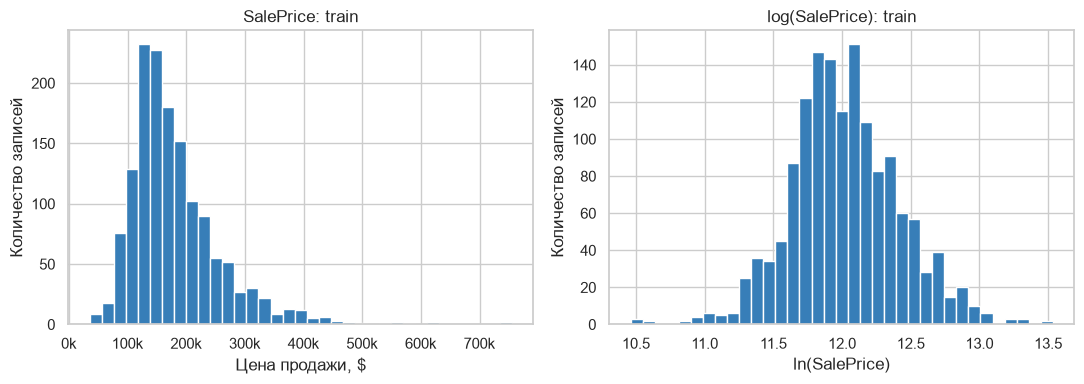

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(train.SalePrice, bins=35, color="#377eb8", edgecolor="white")
axes[0].set(title="SalePrice: train", xlabel="Цена продажи, $", ylabel="Количество записей")
axes[0].xaxis.set_major_formatter(price_formatter)
axes[1].hist(eda_train.LogSalePrice, bins=35, color="#377eb8", edgecolor="white")
axes[1].set(title="log(SalePrice): train", xlabel="ln(SalePrice)", ylabel="Количество записей")
fig.tight_layout()
plt.show()

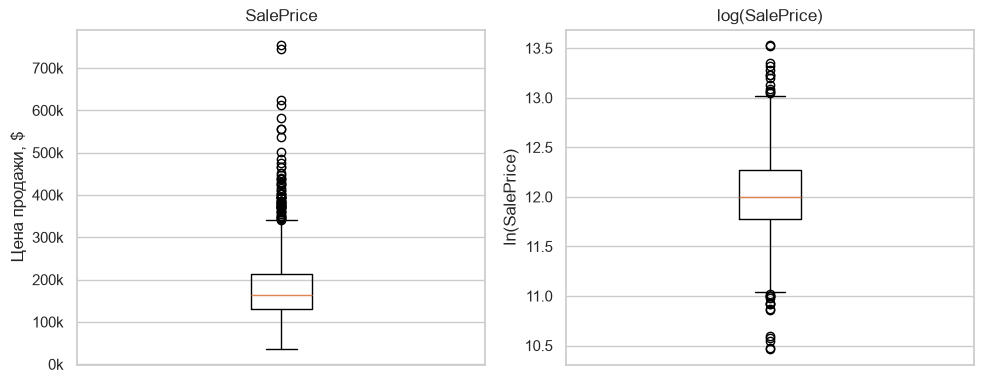

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].boxplot(train.SalePrice)
axes[0].set(title="SalePrice", ylabel="Цена продажи, $")
axes[0].yaxis.set_major_formatter(price_formatter)
axes[1].boxplot(eda_train.LogSalePrice)
axes[1].set(title="log(SalePrice)", ylabel="ln(SalePrice)")
for ax in axes:
    ax.set_xticks([])
fig.tight_layout()
plt.show()

Медиана цены — 163000, среднее — около 180921, диапазон — 34900–755000.
Распределение имеет правый хвост: асимметрия 1.88. После log(SalePrice) она около 0.12.
Пропусков и неположительных цен нет.

Обучение на логарифме цены - гипотеза для CV. Здесь используем именно натуральный log,
не log1p. Потом согласуем это.

In [13]:
price_columns = ["Id", "SalePrice", "OverallQual", "GrLivArea", "Neighborhood", "SaleCondition"]
display(train.nsmallest(5, "SalePrice")[price_columns])
display(train.nlargest(5, "SalePrice")[price_columns])

,Id,SalePrice,OverallQual,GrLivArea,Neighborhood,SaleCondition
495,496,34900,4,720,IDOTRR,Abnorml
916,917,35311,2,480,IDOTRR,Abnorml
968,969,37900,3,968,OldTown,Abnorml
533,534,39300,1,334,BrkSide,Normal
30,31,40000,4,1317,IDOTRR,Normal


,Id,SalePrice,OverallQual,GrLivArea,Neighborhood,SaleCondition
691,692,755000,10,4316,NoRidge,Normal
1182,1183,745000,10,4476,NoRidge,Abnorml
1169,1170,625000,10,3627,NoRidge,Normal
898,899,611657,9,2364,NridgHt,Partial
803,804,582933,9,2822,NridgHt,Partial


## 5. NA, None и настоящие пропуски

In [14]:
token_summary = pd.DataFrame({
    "train_NA": raw_train.eq("NA").sum(),
    "train_None": raw_train.eq("None").sum(),
    "test_NA": raw_test.eq("NA").sum(),
    "test_None": raw_test.eq("None").sum(),
}).reindex(feature_columns).fillna(0).astype(int)
token_summary = token_summary.loc[token_summary.sum(axis=1) > 0]
token_summary["NA_meaning"] = [
    "Отсутствие объекта" if column in absence_na_columns else "Неизвестное значение"
    for column in token_summary.index
]
display(token_summary)

default_train = pd.read_csv(data_dir / "train.csv")
parser_comparison = pd.DataFrame({
    "default_missing": default_train.isna().sum(),
    "unknown_after_semantic_read": train.isna().sum(),
})
display(parser_comparison.loc[parser_comparison.default_missing != parser_comparison.unknown_after_semantic_read])

,train_NA,train_None,test_NA,test_None,NA_meaning
MSZoning,0,0,4,0,Неизвестное значение
LotFrontage,259,0,227,0,Неизвестное значение
Alley,1369,0,1352,0,Отсутствие объекта
Utilities,0,0,2,0,Неизвестное значение
Exterior1st,0,0,1,0,Неизвестное значение
Exterior2nd,0,0,1,0,Неизвестное значение
MasVnrType,8,864,16,878,Неизвестное значение
MasVnrArea,8,0,15,0,Неизвестное значение
BsmtQual,37,0,44,0,Отсутствие объекта
BsmtCond,37,0,45,0,Отсутствие объекта


,default_missing,unknown_after_semantic_read
Alley,1369,0
MasVnrType,872,8
BsmtQual,37,0
BsmtCond,37,0
BsmtExposure,38,0
BsmtFinType1,37,0
BsmtFinType2,38,0
FireplaceQu,690,0
GarageType,81,0
GarageFinish,81,0


В Alley, полях подвала/гаража, FireplaceQu, PoolQC, Fence и MiscFeature
NA по описанию означает отсутствие соответствующего объекта.
В MasVnrType строка None — отсутствие облицовки, а NA — неизвестный тип.
В train 864 значения None в MasVnrType и только 8 неизвестных значений;
обычный read_csv объединяет их в 872 пропуска.

В этом notebook категории отсутствия сохранены.

In [15]:
missing_summary = pd.DataFrame({
    "train_count": train[feature_columns].isna().sum(),
    "train_percent": train[feature_columns].isna().mean() * 100,
    "test_count": test[feature_columns].isna().sum(),
    "test_percent": test[feature_columns].isna().mean() * 100,
})
missing_summary = missing_summary.loc[
    (missing_summary.train_count > 0) | (missing_summary.test_count > 0)
].sort_values("train_percent", ascending=False)
display(missing_summary.round(2))

,train_count,train_percent,test_count,test_percent
LotFrontage,259,17.74,227,15.56
GarageYrBlt,81,5.55,78,5.35
MasVnrType,8,0.55,16,1.10
MasVnrArea,8,0.55,15,1.03
Electrical,1,0.07,0,0.00
Exterior1st,0,0.00,1,0.07
MSZoning,0,0.00,4,0.27
Utilities,0,0.00,2,0.14
BsmtFinSF1,0,0.00,1,0.07
BsmtFinSF2,0,0.00,1,0.07


LotFrontage неизвестен у 259 записей train (17.74%) и 227 test (15.56%).
GarageYrBlt неизвестен у 81 записи train (5.55%) и 78 test (5.35%):
часть неизвестных годов связана с отсутствием гаража, но связь не абсолютная.
MasVnrType и MasVnrArea имеют по 8 неизвестных значений train; Electrical — одно.
В test неизвестные значения встречаются и в полях без пропусков train.

Обработка нужна для всех полей с неизвестными значениями, но важно учесть смысл столбцов.

## 6. Противоречия и допустимые значения

In [16]:
def consistency_masks(frame):
    return {
        "BsmtQual=NA, но TotalBsmtSF>0": frame.BsmtQual.eq("NA") & frame.TotalBsmtSF.gt(0),
        "GarageType=NA, но GarageArea>0": frame.GarageType.eq("NA") & frame.GarageArea.gt(0),
        "PoolQC=NA, но PoolArea>0": frame.PoolQC.eq("NA") & frame.PoolArea.gt(0),
        "FireplaceQu=NA, но Fireplaces>0": frame.FireplaceQu.eq("NA") & frame.Fireplaces.gt(0),
        "MasVnrType=None, но MasVnrArea>0": frame.MasVnrType.eq("None") & frame.MasVnrArea.gt(0),
        "YearBuilt>YrSold": frame.YearBuilt.gt(frame.YrSold),
        "YearRemodAdd>YrSold": frame.YearRemodAdd.gt(frame.YrSold),
        "GarageYrBlt>YrSold": frame.GarageYrBlt.gt(frame.YrSold),
    }

consistency_summary = pd.DataFrame({
    name: {rule: int(mask.sum()) for rule, mask in consistency_masks(frame).items()}
    for name, frame in [("train", train), ("test", test)]
})
display(consistency_summary)

nonnegative_columns = ["LotFrontage", "LotArea", "MasVnrArea", "BsmtFinSF1", "BsmtFinSF2",
                       "BsmtUnfSF", "TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "GrLivArea",
                       "GarageCars", "GarageArea", "PoolArea"]
for name, frame in [("train", train), ("test", test)]:
    assert not frame[nonnegative_columns].lt(0).any().any(), f"Отрицательная площадь/ёмкость в {name}"
    basement_known = frame[["BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF"]].notna().all(axis=1)
    basement_parts = frame.loc[basement_known, ["BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF"]].sum(axis=1)
    print(name, "несовпадения TotalBsmtSF с суммой частей:",
          int((basement_parts != frame.loc[basement_known, "TotalBsmtSF"]).sum()))

display(test.loc[test.GarageYrBlt.gt(test.YrSold), ["Id", "YearBuilt", "GarageYrBlt", "YrSold"]])
display(test.loc[test.PoolQC.eq("NA") & test.PoolArea.gt(0), ["Id", "PoolQC", "PoolArea"]])

,train,test
"BsmtQual=NA, но TotalBsmtSF>0",0,2
"GarageType=NA, но GarageArea>0",0,0
"PoolQC=NA, но PoolArea>0",0,3
"FireplaceQu=NA, но Fireplaces>0",0,0
"MasVnrType=None, но MasVnrArea>0",5,2
YearBuilt>YrSold,0,1
YearRemodAdd>YrSold,1,2
GarageYrBlt>YrSold,0,2


train несовпадения TotalBsmtSF с суммой частей: 0
test несовпадения TotalBsmtSF с суммой частей: 0


,Id,YearBuilt,GarageYrBlt,YrSold
1089,2550,2008,2008.0,2007
1132,2593,2006,2207.0,2007


,Id,PoolQC,PoolArea
960,2421,NA,368
1043,2504,NA,444
1139,2600,NA,561


В test у двух записей BsmtQual=NA при положительной площади подвала,
а у трёх PoolQC=NA при положительной площади бассейна. Информация противоречива.
MasVnrType=None при положительной MasVnrArea встречается 5 раз в train и 2 раза в test.

Есть годы постройки/ремонта позже года продажи; у Id=2593 GarageYrBlt=2207.
Это кандидат на ошибку.
Перед признаками возраста дома/гаража нужно предусмотреть обработку таких записей.

## 7. Числовые признаки и необычные значения

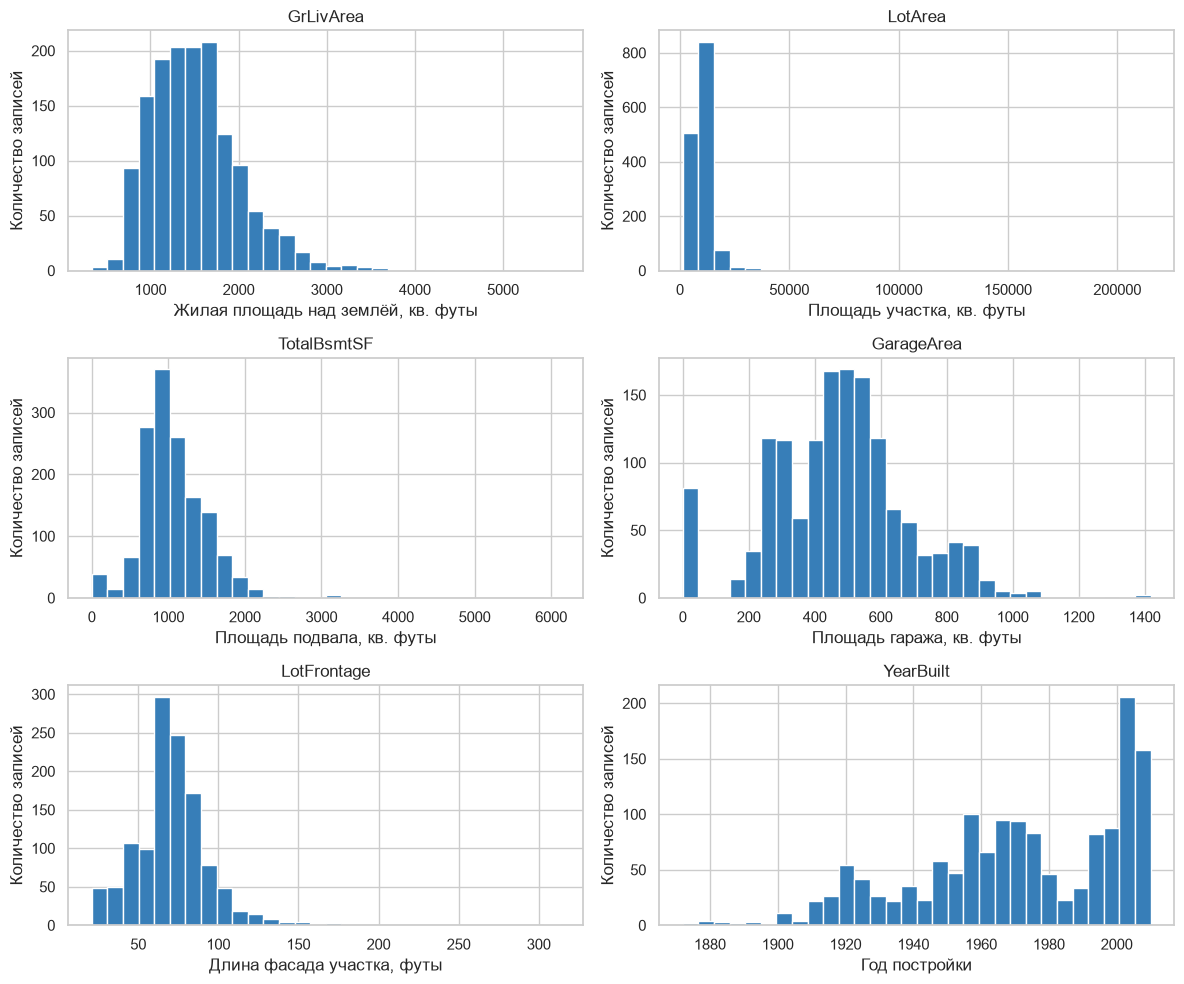

,skew
GrLivArea,1.367
LotArea,12.208
TotalBsmtSF,1.524
GarageArea,0.180
LotFrontage,2.164
YearBuilt,-0.613


In [17]:
numeric_view = ["GrLivArea", "LotArea", "TotalBsmtSF", "GarageArea", "LotFrontage", "YearBuilt"]
numeric_units = {
    "GrLivArea": "Жилая площадь над землёй, кв. футы", "LotArea": "Площадь участка, кв. футы",
    "TotalBsmtSF": "Площадь подвала, кв. футы", "GarageArea": "Площадь гаража, кв. футы",
    "LotFrontage": "Длина фасада участка, футы", "YearBuilt": "Год постройки",
}
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
for ax, column in zip(axes.flat, numeric_view):
    ax.hist(train[column].dropna(), bins=30, color="#377eb8", edgecolor="white")
    ax.set(title=column, xlabel=numeric_units[column], ylabel="Количество записей")
fig.tight_layout()
plt.show()
display(train[numeric_view].skew().round(3).rename("skew").to_frame())

У LotArea очень длинный правый хвост: асимметрия около 12.21.
GrLivArea и TotalBsmtSF также асимметричны, GarageArea ближе к симметричному распределению.
Нулевой размер подвала/гаража скорее всего означает отсутствие объекта.

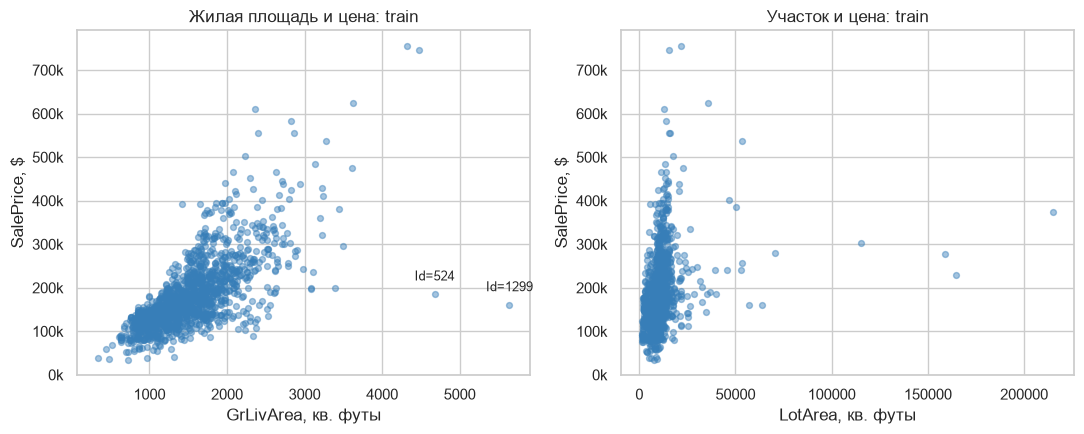

,Id,GrLivArea,OverallQual,SalePrice,SaleCondition
523,524,4676,10,184750,Partial
691,692,4316,10,755000,Normal
1182,1183,4476,10,745000,Abnorml
1298,1299,5642,10,160000,Partial


,Id,LotArea,GrLivArea,SalePrice
313,314,215245,2036,375000
335,336,164660,1786,228950
249,250,159000,2144,277000
706,707,115149,1824,302000
451,452,70761,1533,280000


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(train.GrLivArea, train.SalePrice, alpha=0.45, s=18, color="#377eb8")
axes[0].set(title="Жилая площадь и цена: train", xlabel="GrLivArea, кв. футы", ylabel="SalePrice, $")
axes[0].yaxis.set_major_formatter(price_formatter)
axes[1].scatter(train.LotArea, train.SalePrice, alpha=0.45, s=18, color="#377eb8")
axes[1].set(title="Участок и цена: train", xlabel="LotArea, кв. футы", ylabel="SalePrice, $")
axes[1].yaxis.set_major_formatter(price_formatter)
for passenger_id in [524, 1299]:
    row = train.loc[train.Id.eq(passenger_id)].iloc[0]
    axes[0].annotate(f"Id={passenger_id}", (row.GrLivArea, row.SalePrice),
                     xytext=(0, 10), textcoords="offset points", ha="center", fontsize=9)
fig.tight_layout()
plt.show()
display(train.loc[train.GrLivArea.gt(4000), ["Id", "GrLivArea", "OverallQual", "SalePrice", "SaleCondition"]])
display(train.nlargest(5, "LotArea")[["Id", "LotArea", "GrLivArea", "SalePrice"]])

Площадь жилых помещений связана с ценой сильнее, чем площадь участка.

## 8. Категории и новые значения test

In [19]:
categorical_columns = list(train.select_dtypes(exclude="number").columns) + ["MSSubClass"]
category_summary = pd.DataFrame({
    "n_unique": train[categorical_columns].nunique(),
    "dominant_percent": [
        train[column].value_counts(dropna=False, normalize=True).iloc[0] * 100
        for column in categorical_columns
    ],
}, index=categorical_columns)
display(category_summary.sort_values("n_unique", ascending=False).head(15).round(2))
for column in ["MSZoning", "KitchenQual", "GarageType", "SaleCondition"]:
    print("Признак:", column)
    display(train[column].value_counts(dropna=False).rename("count").to_frame())

,n_unique,dominant_percent
Neighborhood,25,15.41
Exterior2nd,16,34.52
Exterior1st,15,35.27
MSSubClass,15,36.71
SaleType,9,86.78
Condition1,9,86.30
HouseStyle,8,49.73
RoofMatl,8,98.22
Condition2,8,98.97
BsmtFinType1,7,29.45


Признак: MSZoning


,count
MSZoning,
RL,1151
RM,218
FV,65
RH,16
C (all),10


Признак: KitchenQual


,count
KitchenQual,
TA,735
Gd,586
Ex,100
Fa,39


Признак: GarageType


,count
GarageType,
Attchd,870
Detchd,387
BuiltIn,88
NA,81
Basment,19
CarPort,9
2Types,6


Признак: SaleCondition


,count
SaleCondition,
Normal,1198
Partial,125
Abnorml,101
Family,20
Alloca,12
AdjLand,4


In [20]:
novel_rows = []
for column in categorical_columns:
    train_categories = set(train[column].dropna().unique())
    test_values = test[column].dropna()
    new_categories = set(test_values.unique()) - train_categories
    if new_categories:
        novel_rows.append({
            "feature": column, "new_categories": sorted(new_categories),
            "test_rows": int(test_values.isin(new_categories).sum()),
        })
novel_categories = pd.DataFrame(novel_rows, columns=["feature", "new_categories", "test_rows"])
display(novel_categories)

,feature,new_categories,test_rows
0,MSSubClass,[150],1


Neighborhood содержит 25 категорий. Многие категориальные признаки имеют редкие значения.
Среди известных текстовых категорий test нет новых по сравнению с train.
Но числовой код MSSubClass=150 встречается только в test: кодировщик должен обработать неизвестную категорию.
NA как категория отсутствия участвует в сравнении.

## 9. Качество дома и цена

,count,mean,median
OverallQual,,,
1,2,50150.00,50150.0
2,3,51770.33,60000.0
3,20,87473.75,86250.0
4,116,108420.66,108000.0
5,397,133523.35,133000.0
6,374,161603.03,160000.0
7,319,207716.42,200141.0
8,168,274735.54,269750.0
9,43,367513.02,345000.0


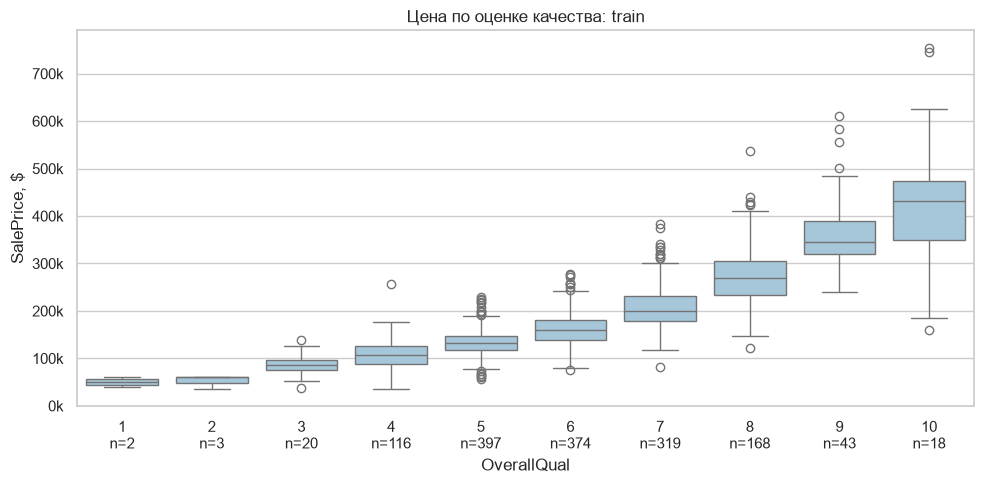

In [21]:
quality_summary = train.groupby("OverallQual").SalePrice.agg(count="count", mean="mean", median="median")
display(quality_summary.round(2))
quality_order = sorted(train.OverallQual.unique())
quality_labels = [f"{quality}\nn={quality_summary.loc[quality, 'count']}" for quality in quality_order]
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=train, x="OverallQual", y="SalePrice", order=quality_order, color="#9ecae1", ax=ax)
ax.set(title="Цена по оценке качества: train", xlabel="OverallQual", ylabel="SalePrice, $")
ax.set_xticks(range(len(quality_order)), labels=quality_labels)
ax.yaxis.set_major_formatter(price_formatter)
fig.tight_layout()
plt.show()

Медианная цена растёт с OverallQual: для оценки 5 — 133000, для 7 — 200141, для 9 — 345000.
При оценках 1 и 2 всего 2 и 3 записи: их статистики менее устойчивы.
OverallQual — важный кандидат для baseline. Это наблюдаемая связь, не оценка причинного эффекта качества.

## 10. Район, кухня и гараж

,count,mean,median
Neighborhood,,,
MeadowV,17,98576.47,88000.0
IDOTRR,37,100123.78,103000.0
BrDale,16,104493.75,106000.0
OldTown,113,128225.30,119000.0
Edwards,100,128219.70,121750.0
BrkSide,58,124834.05,124300.0
Sawyer,74,136793.14,135000.0
Blueste,2,137500.00,137500.0
SWISU,25,142591.36,139500.0


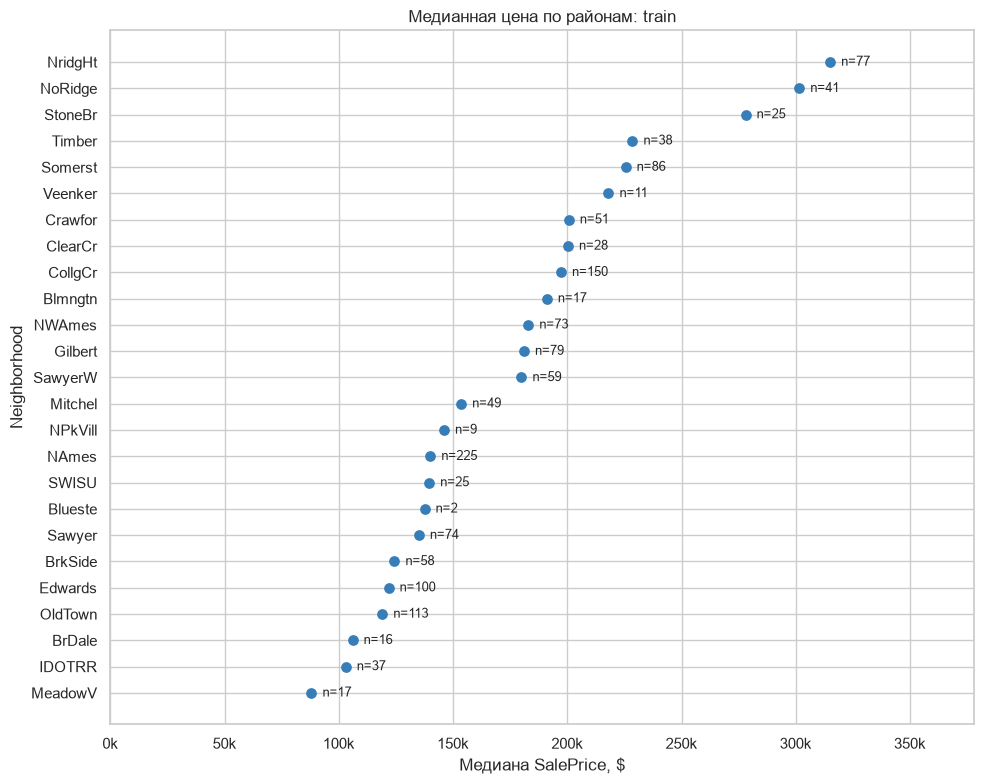

In [22]:
neighborhood_summary = train.groupby("Neighborhood").SalePrice.agg(
    count="count", mean="mean", median="median",
).sort_values("median")
display(neighborhood_summary.round(2))
fig, ax = plt.subplots(figsize=(10, 8))
positions = np.arange(len(neighborhood_summary))
ax.scatter(neighborhood_summary["median"], positions, color="#377eb8", s=45)
ax.set_yticks(positions, labels=neighborhood_summary.index)
for position, (_, row) in enumerate(neighborhood_summary.iterrows()):
    ax.annotate(f"n={int(row['count'])}", (row['median'], position),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=9)
ax.set(title="Медианная цена по районам: train", xlabel="Медиана SalePrice, $", ylabel="Neighborhood",
       xlim=(0, neighborhood_summary['median'].max() * 1.2))
ax.xaxis.set_major_formatter(price_formatter)
fig.tight_layout()
plt.show()

Медианы различаются от 88000 в MeadowV (17 записей) до 315000 в NridgHt (77 записей).
Neighborhood связан с ценой, но районы отличаются также качеством и размером домов.
Медиана Blueste основана всего на двух записях.

,count,median
KitchenQual,,
Ex,100,316750.0
Fa,39,115000.0
Gd,586,201400.0
TA,735,137000.0


,count,median
GarageType,,
2Types,6,159000.0
Attchd,870,185000.0
Basment,19,148000.0
BuiltIn,88,227500.0
CarPort,9,108000.0
Detchd,387,129500.0
NA,81,100000.0


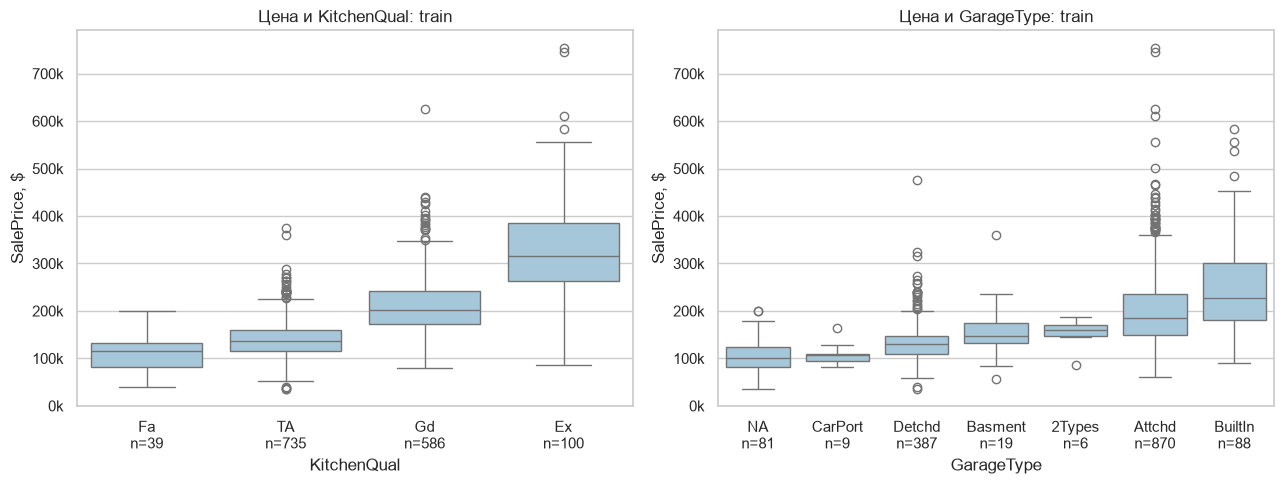

In [23]:
kitchen_summary = train.groupby("KitchenQual").SalePrice.agg(count="count", median="median")
garage_summary = train.groupby("GarageType").SalePrice.agg(count="count", median="median")
display(kitchen_summary.round(2))
display(garage_summary.round(2))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
kitchen_order = [category for category in ["Po", "Fa", "TA", "Gd", "Ex"] if category in kitchen_summary.index]
garage_order = garage_summary.sort_values("median").index.tolist()
for ax, column, order, summary in [
    (axes[0], "KitchenQual", kitchen_order, kitchen_summary),
    (axes[1], "GarageType", garage_order, garage_summary),
]:
    sns.boxplot(data=train, x=column, y="SalePrice", order=order, color="#9ecae1", ax=ax)
    labels = [f"{category}\nn={summary.loc[category, 'count']}" for category in order]
    ax.set_xticks(range(len(order)), labels=labels)
    ax.set(title=f"Цена и {column}: train", xlabel=column, ylabel="SalePrice, $")
    ax.yaxis.set_major_formatter(price_formatter)
fig.tight_layout()
plt.show()

Для KitchenQual медианы растут от 115000 у Fa до 316750 у Ex.
У записей GarageType=NA медиана — 100000; NA здесь обозначает отсутствие гаража по словарю.
Тип гаража и качество кухни связаны с ценой, но другие свойства домов не выровнены.
У редких категорий проценты/средние и медианы нестабильны: учитываем n.

## 11. Корреляции числовых полей

,Pearson_price,Pearson_log_price,Spearman_price
OverallQual,0.791,0.817,0.810
GrLivArea,0.709,0.701,0.731
GarageCars,0.640,0.681,0.691
GarageArea,0.623,0.651,0.649
TotalBsmtSF,0.614,0.612,0.603
1stFlrSF,0.606,0.597,0.575
FullBath,0.561,0.595,0.636
YearBuilt,0.523,0.587,0.653
YearRemodAdd,0.507,0.566,0.571
GarageYrBlt,0.486,0.541,0.594


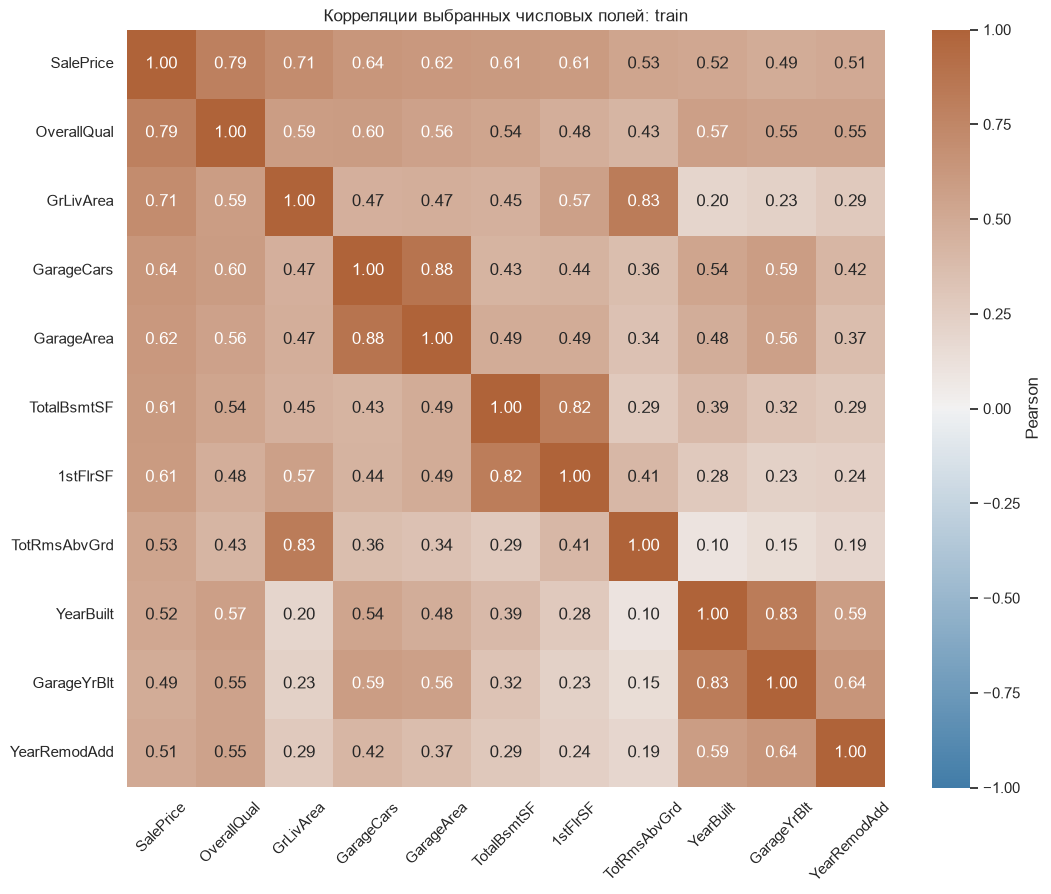

In [24]:
numeric_columns = train.select_dtypes(include="number").columns.drop(
    ["Id", "SalePrice", "MSSubClass", "MoSold"], errors="ignore",
)
target_correlations = pd.DataFrame({
    "Pearson_price": train[numeric_columns].corrwith(train.SalePrice),
    "Pearson_log_price": train[numeric_columns].corrwith(eda_train.LogSalePrice),
    "Spearman_price": train[numeric_columns].corrwith(train.SalePrice, method="spearman"),
})
correlation_order = target_correlations.Pearson_log_price.abs().sort_values(ascending=False).index
display(target_correlations.loc[correlation_order].head(16).round(3))

heatmap_columns = ["SalePrice", "OverallQual", "GrLivArea", "GarageCars", "GarageArea",
                   "TotalBsmtSF", "1stFlrSF", "TotRmsAbvGrd", "YearBuilt", "GarageYrBlt", "YearRemodAdd"]
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(train[heatmap_columns].corr(), vmin=-1, vmax=1, center=0,
            cmap=sns.diverging_palette(240, 30, as_cmap=True), annot=True, fmt=".2f", square=True,
            cbar_kws={"label": "Pearson"}, ax=ax)
ax.set_title("Корреляции выбранных числовых полей: train")
ax.tick_params(axis="x", labelrotation=45)
ax.tick_params(axis="y", labelrotation=0)
fig.tight_layout()
plt.show()

In [25]:
feature_correlations = train[numeric_columns].corr()
upper_mask = np.triu(np.ones(feature_correlations.shape, dtype=bool), k=1)
correlated_pairs = feature_correlations.where(upper_mask).stack()
high_correlation_pairs = correlated_pairs[correlated_pairs.abs() >= 0.8]
display(high_correlation_pairs.rename("Pearson").to_frame().round(3))

,,Pearson
YearBuilt,GarageYrBlt,0.826
TotalBsmtSF,1stFlrSF,0.820
GrLivArea,TotRmsAbvGrd,0.825
GarageCars,GarageArea,0.882


С log(SalePrice) наиболее выражена линейная связь OverallQual (0.817),
GrLivArea (0.701), GarageCars (0.681) и GarageArea (0.651).

Есть четыре пары с |Pearson| ≥ 0.8: GarageCars–GarageArea, GrLivArea–TotRmsAbvGrd,
YearBuilt–GarageYrBlt, TotalBsmtSF–1stFlrSF. Для линейных моделей это повод проверить
регуляризацию и отбор.
Корреляции считаются по попарно заполненным строкам; текстовые категории в матрицу не входят.

## 12. Константы и почти константные признаки

In [26]:
constant_columns = [column for column in feature_columns if train[column].nunique(dropna=False) <= 1]
dominant_share = pd.Series({
    column: train[column].value_counts(dropna=False, normalize=True).iloc[0]
    for column in feature_columns
})
dominant_columns = dominant_share[dominant_share >= 0.95].sort_values(ascending=False)
print("Константные признаки:", constant_columns)
display(dominant_columns.mul(100).round(2).rename("dominant_percent").to_frame())

Константные признаки: []


,dominant_percent
Utilities,99.93
Street,99.59
PoolArea,99.52
PoolQC,99.52
Condition2,98.97
3SsnPorch,98.36
RoofMatl,98.22
LowQualFinSF,98.22
Heating,97.81
MiscVal,96.44


Константных признаков нет. При пороге 95% найдено 12 почти константных полей.
Utilities принимает AllPub у 1459 из 1460 записей train.
PoolQC и PoolArea почти постоянны, потому что бассейн редок; это не автоматически бесполезные поля.
Отбор по частотам — гипотеза для CV. Список удаляемых колонок определяем внутри train-фолда.

## 13. Сопоставимость train/test

count      mean     50%     min       max
dataset feature                                                
train   GrLivArea    1460.0   1515.46  1464.0   334.0    5642.0
        LotArea      1460.0  10516.83  9478.5  1300.0  215245.0
        TotalBsmtSF  1460.0   1057.43   991.5     0.0    6110.0
        GarageArea   1460.0    472.98   480.0     0.0    1418.0
        LotFrontage  1201.0     70.05    69.0    21.0     313.0
        YearBuilt    1460.0   1971.27  1973.0  1872.0    2010.0
test    GrLivArea    1459.0   1486.05  1432.0   407.0    5095.0
        LotArea      1459.0   9819.16  9399.0  1470.0   56600.0
        TotalBsmtSF  1458.0   1046.12   988.0     0.0    5095.0
        GarageArea   1458.0    472.77   480.0     0.0    1488.0
        LotFrontage  1232.0     68.58    67.0    21.0     200.0
        YearBuilt    1459.0   1971.36  1973.0  1879.0    2010.0

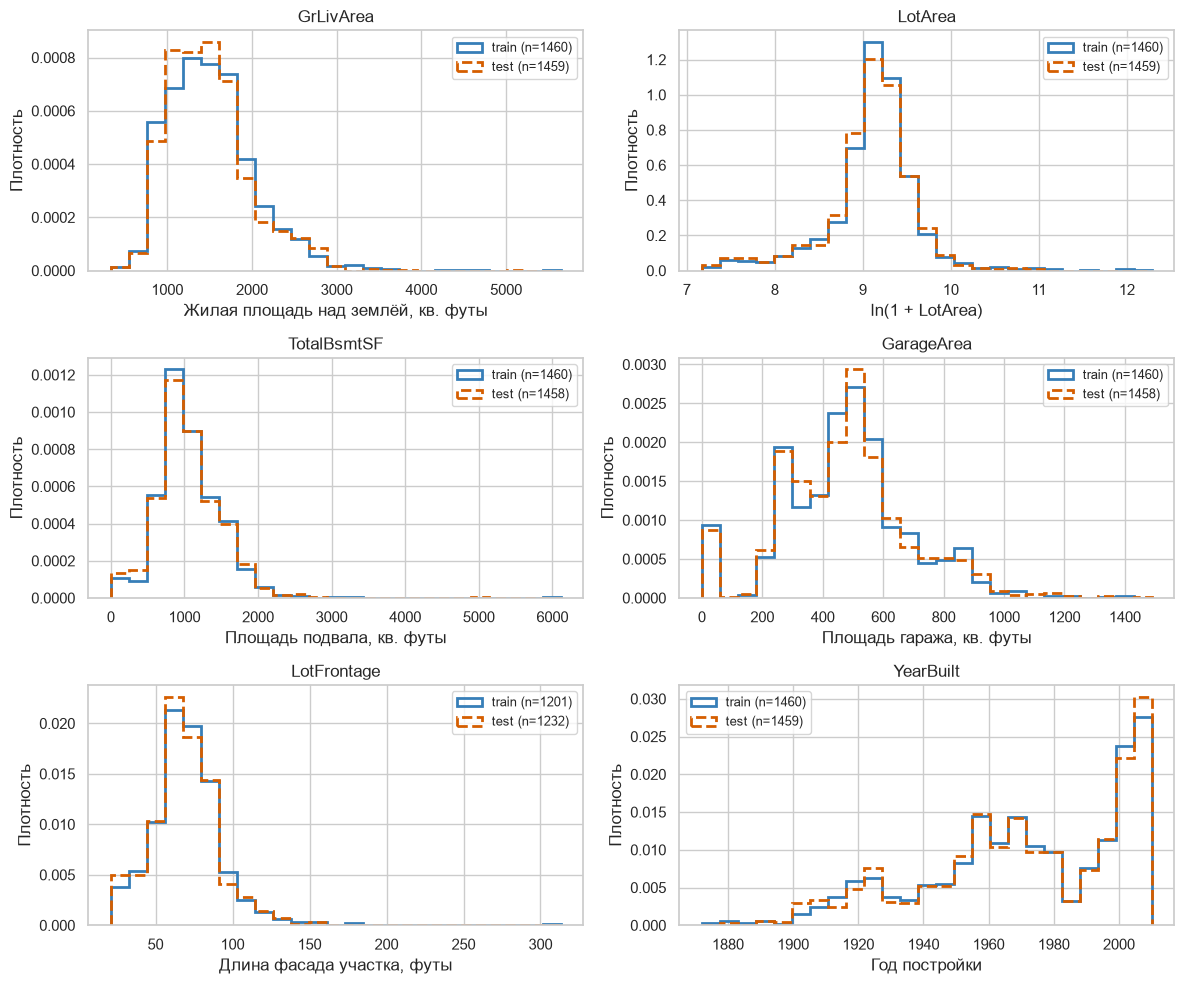

In [27]:
distribution_summary = pd.concat({
    "train": train[numeric_view].describe().T,
    "test": test[numeric_view].describe().T,
}, names=["dataset", "feature"])
display(distribution_summary[["count", "mean", "50%", "min", "max"]].round(2))

fig, axes = plt.subplots(3, 2, figsize=(12, 10))
for ax, column in zip(axes.flat, numeric_view):
    transform = np.log1p if column == "LotArea" else lambda values: values
    train_values = transform(train[column].dropna())
    test_values = transform(test[column].dropna())
    common_bins = np.histogram_bin_edges(pd.concat([train_values, test_values]), bins=25)
    ax.hist(train_values, bins=common_bins, density=True, histtype="step", linewidth=2,
            color="#377eb8", label=f"train (n={len(train_values)})")
    ax.hist(test_values, bins=common_bins, density=True, histtype="step", linewidth=2,
            color="#d55e00", linestyle="--", label=f"test (n={len(test_values)})")
    xlabel = "ln(1 + LotArea)" if column == "LotArea" else numeric_units[column]
    ax.set(title=column, xlabel=xlabel, ylabel="Плотность")
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

In [28]:
category_shares = {}
for column in ["MSZoning", "Neighborhood", "OverallQual"]:
    shares = pd.concat({
        "train_percent": train[column].fillna("Unknown").value_counts(normalize=True) * 100,
        "test_percent": test[column].fillna("Unknown").value_counts(normalize=True) * 100,
    }, axis=1).fillna(0)
    shares["difference_pp"] = shares.test_percent - shares.train_percent
    category_shares[column] = shares
    print("Доли категорий:", column)
    order = shares.difference_pp.abs().sort_values(ascending=False).index
    display(shares.loc[order].head(10).round(2))

Доли категорий: MSZoning


,train_percent,test_percent,difference_pp
MSZoning,,,
RL,78.84,76.35,-2.48
RM,14.93,16.59,1.66
FV,4.45,5.07,0.62
RH,1.10,0.69,-0.41
C (all),0.68,1.03,0.34
Unknown,0.00,0.27,0.27


Доли категорий: Neighborhood


,train_percent,test_percent,difference_pp
Neighborhood,,,
CollgCr,10.27,8.02,-2.25
IDOTRR,2.53,3.84,1.30
Mitchel,3.36,4.46,1.10
NWAmes,5.00,3.98,-1.02
OldTown,7.74,8.64,0.90
NridgHt,5.27,6.10,0.83
ClearCr,1.92,1.10,-0.82
NoRidge,2.81,2.06,-0.75
Somerst,5.89,6.58,0.69


Доли категорий: OverallQual


,train_percent,test_percent,difference_pp
OverallQual,,,
7,21.85,19.26,-2.59
5,27.19,29.34,2.14
9,2.95,4.39,1.44
6,25.62,24.47,-1.15
2,0.21,0.69,0.48
8,11.51,11.93,0.42
4,7.95,7.54,-0.41
10,1.23,0.89,-0.34
3,1.37,1.37,0.00


Основные области распределений train/test похожи, но частоты, крайние значения и пропуски различаются.
На графиках показана плотность: каждый набор нормируется отдельно, высота не равна доле записей.
Для LotArea изменён только масштаб визуализации — log1p.

## 14. Время продажи и риск утечки

,train,test
YrSold,,
2006,314,305
2007,329,363
2008,304,318
2009,338,309
2010,175,164


,count,median,mean
YrSold,,,
2006,314,163995.0,182549.46
2007,329,167000.0,186063.15
2008,304,164000.0,177360.84
2009,338,162000.0,179432.10
2010,175,155000.0,177393.67


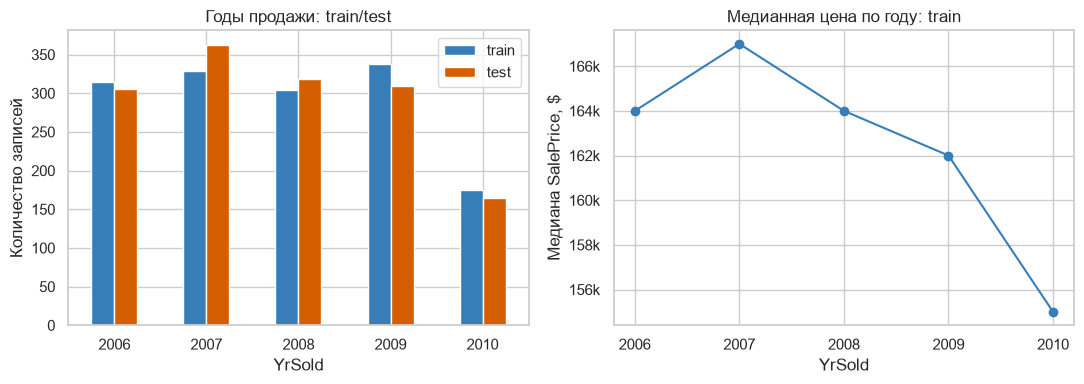

In [29]:
year_counts = pd.concat({
    "train": train.YrSold.value_counts().sort_index(),
    "test": test.YrSold.value_counts().sort_index(),
}, axis=1).fillna(0).astype(int)
year_summary = train.groupby("YrSold").SalePrice.agg(count="count", median="median", mean="mean")
display(year_counts)
display(year_summary.round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
year_counts.plot(kind="bar", color=["#377eb8", "#d55e00"], ax=axes[0], rot=0)
axes[0].set(title="Годы продажи: train/test", xlabel="YrSold", ylabel="Количество записей")
axes[1].plot(year_summary.index, year_summary['median'], marker="o", color="#377eb8")
axes[1].set(title="Медианная цена по году: train", xlabel="YrSold", ylabel="Медиана SalePrice, $")
axes[1].set_xticks(year_summary.index)
axes[1].yaxis.set_major_formatter(price_formatter)
fig.tight_layout()
plt.show()

Оба набора включают продажи 2006–2010 годов: test не является просто более поздним периодом.

## 15. Итог

Наиболее выраженные связи с ценой обнаружены у качества дома, жилой площади, гаража и района.
SalePrice имеет правый хвост, который заметно уменьшается после логарифмирования.
Данные содержат категории отсутствия объектов, неизвестные значения и отдельные противоречия.

### Структура и качество данных

В train 1460 записей и 81 столбец, в test 1459 и 80. SalePrice — таргет, Id — идентификатор.
Внутри наборов точных повторов признаков нет; между train/test есть две пары совпадающих описаний.
Константных полей нет, почти константных при пороге 95% — 12.

### Таргет и числовые признаки

Медианная цена — 163000, средняя — около 180921. Асимметрия SalePrice — 1.88,
log(SalePrice) — 0.12. Логарифмирование таргета проверим на CV после согласования формулки.
Жилая площадь связана с ценой, но есть крупные дома с необычно низкими ценами.
У LotArea длинный правый хвост.

### Пропуски и категории

NA не имеет единого смысла во всех столбцах. По описанию полей он может означать отсутствие
подвала, гаража, бассейна и других объектов. None в MasVnrType — отсутствие облицовки;
неизвестный MasVnrType встречается только у 8 записей train, а не у 872.
LotFrontage неизвестен у 17.74% train и 15.56% test.
Есть NA при положительной площади объекта и несогласованные даты, включая GarageYrBlt=2207 в test.
В test есть новый код MSSubClass=150; encoding должен предусмотреть неизвестные категории.

### Связи с ценой

Медианная цена растёт с OverallQual; районы и категории качества кухни также различаются.
Размеры групп показаны рядом со статистиками: для редких категорий выводы менее устойчивы.
Выявлены четыре сильно коррелирующие числовые пары. Регуляризация и отбор — отдельные гипотезы.

### Гипотезы

- Согласовать чтение NA/None с data_description.txt перед первым baseline.
- Проверить обучение на log(SalePrice), обработку неизвестных значений и индикаторы пропусков.
- Сравнить способы кодирования обычных и упорядоченных категорий, предусмотрев новые значения.
- Проверить log1p площадей, регуляризацию и отбор почти константных/коррелирующих полей.
 
Все улучшения проверяем по одному на одних и тех же фолдах.
Исходные данные не изменены, модели и submission не созданы.

### 15.1. Финальная проверка воспроизводимости

In [31]:
pd.testing.assert_frame_equal(train, train_snapshot)
pd.testing.assert_frame_equal(test, test_snapshot)
assert train.shape == (1460, 81) and test.shape == (1459, 80)
for summary in [quality_summary, neighborhood_summary, kitchen_summary, garage_summary, year_summary]:
    assert summary['count'].sum() == len(train), "Группы потеряли записи"
assert len(high_correlation_pairs) == 4
assert len(dominant_columns) == 12
assert len(overlap) == 2
assert train.MasVnrType.isna().sum() == 8
assert raw_train.MasVnrType.eq("None").sum() == 864
assert train.SalePrice.median() == 163000
print("EDA выполнен: проверки пройдены, исходные train/test не поменялись -> ничего не сломали.")

EDA выполнен: проверки пройдены, исходные train/test не поменялись -> ничего не сломали.
